# Tugas 2

#### Mata Kuliah: Pemrosesan Paralel 
#### Nama / NIM: Raudhatul Jannah / 2411512016

## 1. Dining Philosophers dengan N Berbeda

In [1]:
import threading
import time

def jalankan_arbitrator(N, putaran=20, waktu_makan=0.02, waktu_pikir=0.01):
    """Solusi arbitrator (Semaphore N-1) untuk N filsuf. Mengembalikan (total_makan, durasi, puncak_makan_bersamaan)."""
    forks = [threading.Lock() for _ in range(N)]
    kursi_meja = threading.Semaphore(N - 1)
    jumlah_makan = [0] * N
    m = threading.Lock()
    sedang_makan = [0]
    puncak = [0]

    def filsuf(i):
        kiri, kanan = forks[i], forks[(i + 1) % N]
        for _ in range(putaran):
            with kursi_meja:
                with kiri:
                    with kanan:
                        with m:
                            sedang_makan[0] += 1
                            puncak[0] = max(puncak[0], sedang_makan[0])
                        jumlah_makan[i] += 1
                        time.sleep(waktu_makan)      # "makan"
                        with m:
                            sedang_makan[0] -= 1
            time.sleep(waktu_pikir)                  # "berpikir"

    threads = [threading.Thread(target=filsuf, args=(i,)) for i in range(N)]
    t0 = time.perf_counter()
    for t in threads: t.start()
    for t in threads: t.join()
    durasi = time.perf_counter() - t0

    total = sum(jumlah_makan)
    assert total == N * putaran, "ada filsuf yang tidak selesai (deadlock?)"
    return total, durasi, puncak[0]

ULANGAN = 3
hasil_throughput = {}
print(f"{'N':>3} | {'total makan':>11} | {'durasi (s)':>10} | {'throughput (makan/s)':>20} | {'puncak makan bersamaan':>22} | {'batas teori N//2':>16}")
print("-" * 98)
for N in [3, 5, 7, 10]:
    run = [jalankan_arbitrator(N) for _ in range(ULANGAN)]
    total = run[0][0]
    durasi = sum(r[1] for r in run) / ULANGAN
    puncak = max(r[2] for r in run)
    tp = total / durasi
    hasil_throughput[N] = tp
    print(f"{N:>3} | {total:>11} | {durasi:>10.2f} | {tp:>20.1f} | {puncak:>22} | {N // 2:>16}")

print()
base = hasil_throughput[3]
for N, tp in hasil_throughput.items():
    print(f"N={N:>2}: throughput {tp:6.1f}/s | naik {tp/base:4.2f}x vs N=3 | N naik {N/3:4.2f}x | throughput per filsuf {tp/N:5.1f}/s")

  N | total makan | durasi (s) | throughput (makan/s) | puncak makan bersamaan | batas teori N//2
--------------------------------------------------------------------------------------------------
  3 |          60 |       1.22 |                 49.0 |                      1 |                1
  5 |         100 |       1.04 |                 96.6 |                      2 |                2
  7 |         140 |       0.96 |                145.5 |                      3 |                3
 10 |         200 |       0.82 |                243.7 |                      5 |                5

N= 3: throughput   49.0/s | naik 1.00x vs N=3 | N naik 1.00x | throughput per filsuf  16.3/s
N= 5: throughput   96.6/s | naik 1.97x vs N=3 | N naik 1.67x | throughput per filsuf  19.3/s
N= 7: throughput  145.5/s | naik 2.97x vs N=3 | N naik 2.33x | throughput per filsuf  20.8/s
N=10: throughput  243.7/s | naik 4.97x vs N=3 | N naik 3.33x | throughput per filsuf  24.4/s


Grafik berikut membandingkan throughput terukur dengan garis linear (acuan dari N=3) dan batas atas teoretis.

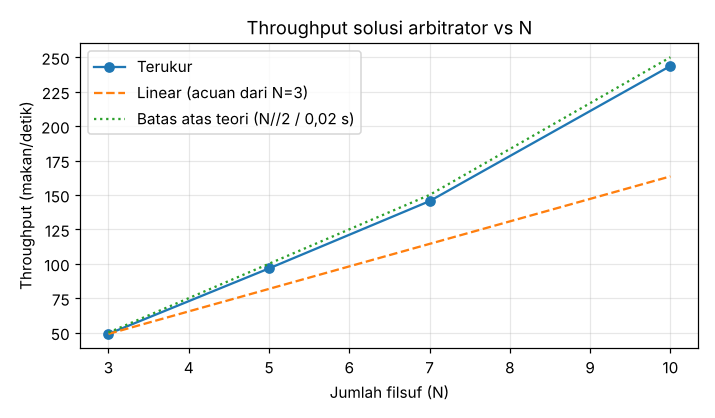

In [2]:
import matplotlib.pyplot as plt

Ns = list(hasil_throughput.keys())
tps = [hasil_throughput[n] for n in Ns]
linear = [hasil_throughput[3] * n / 3 for n in Ns]      # jika throughput naik linear terhadap N (acuan dari N=3)
teori = [(n // 2) / 0.02 for n in Ns]                    # batas atas: N//2 filsuf makan bersamaan, 0,02 s per makan

plt.figure(figsize=(6.5, 3.8))
plt.plot(Ns, tps, "o-", label="Terukur")
plt.plot(Ns, linear, "--", label="Linear (acuan dari N=3)")
plt.plot(Ns, teori, ":", label="Batas atas teori (N//2 / 0,02 s)")
plt.xlabel("Jumlah filsuf (N)"); plt.ylabel("Throughput (makan/detik)")
plt.title("Throughput solusi arbitrator vs N"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

### Tidak, throughput tidak naik linear terhadap N. Throughput naik, tetapi mengikuti ⌊N/2⌋, bukan N.

1. Setiap filsuf butuh 2 garpu dari total N garpu, sehingga paling banyak ⌊N/2⌋ filsuf bisa makan bersamaan. Kolom `puncak makan bersamaan` membuktikannya: 1, 2, 3, 5 untuk N = 3, 5, 7, 10. Batas atas throughput adalah ⌊N/2⌋ ÷ 0,02 s = ⌊N/2⌋ × 50 makan/detik, dan hasil terukur berada sekitar 97–98% dari batas itu. Selisih kecilnya berasal dari overhead penjadwalan thread dan `time.sleep` yang tidak presisi.
2. Rasio throughput antar-N sama dengan rasio ⌊N/2⌋. Dari N=3 ke N=10, N naik 3,33× tetapi throughput naik sekitar 5×, tepat sebesar 5/1. Pada N ganjil satu garpu selalu menganggur, sehingga N=3 kurang efisien (hanya 1 dari 3 garpu terpakai oleh pasangan yang makan).
3. Throughput per filsuf mendekati batas 25 makan/detik (= 1 ÷ (2 × 0,02 s)), dengan efisiensi garpu 2⌊N/2⌋/N: N=3 → 67%, N=5 → 80%, N=7 → 86%, N=10 → 100%. Angka teorinya (≈16,7; 20; 21,4; 25) cocok dengan hasil terukur.
4. Arbitrator bukan bottleneck. Pembatas sebenarnya adalah jumlah garpu (resource fisik). Karena ⌊N/2⌋ ≤ N−1, `Semaphore(N-1)` tidak pernah menahan filsuf yang sebenarnya bisa makan; tugasnya hanya mencegah deadlock.
5. Makan disimulasikan dengan `time.sleep`, yang melepas GIL. Jika "makan" berupa komputasi CPU murni di Python, GIL akan menjadi batas tambahan dan throughput tidak akan naik seperti ini.

## 2️. Readers-Writers dengan Prioritas Writer

In [3]:
import threading
import time
import random

class RWPrioritasWriter:
    """Readers-Writers dengan PRIORITAS WRITER (Second Readers-Writers Problem, Courtois dkk. 1971).

    - baca_masuk  : "gerbang" reader. Writer pertama yang datang MENUTUP gerbang ini,
                    sehingga reader BARU tertahan selama masih ada writer yang menunggu/menulis.
    - resource    : akses eksklusif ke data (dipegang reader pertama ATAU satu writer).
    - writecount  : jumlah writer yang sedang menunggu/menulis; gerbang baru dibuka oleh writer TERAKHIR.
    """
    def __init__(self):
        self.baca_masuk = threading.Lock()
        self.resource = threading.Lock()
        self.mutex_r = threading.Lock()
        self.mutex_w = threading.Lock()
        self.readcount = 0
        self.writecount = 0

    def mulai_baca(self):
        with self.baca_masuk:                 # reader baru harus melewati gerbang
            with self.mutex_r:
                self.readcount += 1
                if self.readcount == 1:
                    self.resource.acquire()   # reader pertama mengunci writer

    def selesai_baca(self):
        with self.mutex_r:
            self.readcount -= 1
            if self.readcount == 0:
                self.resource.release()       # reader terakhir membuka untuk writer

    def mulai_tulis(self):
        with self.mutex_w:
            self.writecount += 1
            if self.writecount == 1:
                self.baca_masuk.acquire()     # writer pertama MENUTUP gerbang reader
        self.resource.acquire()               # tunggu reader yang sudah di dalam selesai

    def selesai_tulis(self):
        self.resource.release()
        with self.mutex_w:
            self.writecount -= 1
            if self.writecount == 0:
                self.baca_masuk.release()     # writer terakhir MEMBUKA gerbang

print("Kelas RWPrioritasWriter siap dipakai.")

Kelas RWPrioritasWriter siap dipakai.


**Uji 1. Kebenaran.** 5 reader dan 3 writer berjalan bersamaan. Setiap akses dicek: writer tidak boleh bertemu reader atau writer lain, dan reader tidak boleh masuk saat ada writer. Nilai akhir harus sama dengan jumlah penulisan.

In [4]:
def uji_kebenaran(n_reader=5, n_writer=3, iterasi=15):
    rw = RWPrioritasWriter()
    data = {"nilai": 0}
    st = {"reader_aktif": 0, "writer_aktif": 0, "pelanggaran": 0}
    sm = threading.Lock()

    def reader():
        for _ in range(iterasi):
            rw.mulai_baca()
            with sm:
                st["reader_aktif"] += 1
                if st["writer_aktif"] > 0:          # reader tidak boleh masuk saat ada writer
                    st["pelanggaran"] += 1
            time.sleep(random.uniform(0.001, 0.005))
            with sm:
                st["reader_aktif"] -= 1
            rw.selesai_baca()
            time.sleep(random.uniform(0, 0.003))

    def writer():
        for _ in range(iterasi):
            rw.mulai_tulis()
            with sm:
                if st["writer_aktif"] > 0 or st["reader_aktif"] > 0:   # writer harus eksklusif
                    st["pelanggaran"] += 1
                st["writer_aktif"] += 1
            nilai = data["nilai"]; time.sleep(0.001); data["nilai"] = nilai + 1   # read-modify-write sengaja "rawan"
            with sm:
                st["writer_aktif"] -= 1
            rw.selesai_tulis()
            time.sleep(random.uniform(0, 0.003))

    threads = [threading.Thread(target=reader) for _ in range(n_reader)]
    threads += [threading.Thread(target=writer) for _ in range(n_writer)]
    for t in threads: t.start()
    for t in threads: t.join()
    return data["nilai"], n_writer * iterasi, st["pelanggaran"]

random.seed(7)
nilai, harapan, pelanggaran = uji_kebenaran()
print(f"Nilai akhir      : {nilai} (harus {harapan})")
print(f"Pelanggaran akses: {pelanggaran} (harus 0)")
print("HASIL:", "BENAR" if nilai == harapan and pelanggaran == 0 else "SALAH")

Nilai akhir      : 45 (harus 45)
Pelanggaran akses: 0 (harus 0)
HASIL: BENAR


**Uji 2. Starvation reader.** 3 writer menulis terus-menerus tanpa jeda (selalu ada writer yang menunggu), lalu satu reader datang. Jika reader tidak masuk dalam 1,5 detik, starvation terbukti.

In [5]:
def uji_starvation_reader(batas_tunggu=1.5, n_writer=3):
    rw = RWPrioritasWriter()
    berhenti = threading.Event()
    reader_masuk = threading.Event()
    jumlah_tulis = [0]
    waktu_tunggu = [None]

    def penulis_terus_menerus():
        while not berhenti.is_set():
            rw.mulai_tulis()
            jumlah_tulis[0] += 1
            time.sleep(0.01)
            rw.selesai_tulis()               # langsung loop lagi tanpa jeda -> selalu ada writer menunggu

    def satu_pembaca():
        t0 = time.perf_counter()
        rw.mulai_baca()
        waktu_tunggu[0] = time.perf_counter() - t0
        reader_masuk.set()
        rw.selesai_baca()

    writers = [threading.Thread(target=penulis_terus_menerus) for _ in range(n_writer)]
    for t in writers: t.start()
    time.sleep(0.1)                           # biarkan writer ramai duluan
    reader = threading.Thread(target=satu_pembaca)
    reader.start()

    reader_masuk.wait(timeout=batas_tunggu)
    if not reader_masuk.is_set():
        print(f"Reader BELUM juga dapat giliran setelah {batas_tunggu} detik -- STARVATION READER TERBUKTI!")
    else:
        print("Reader berhasil masuk (starvation tidak terjadi).")
    tulis_saat_menunggu = jumlah_tulis[0]

    berhenti.set()                            # hentikan writer -> gerbang akhirnya dibuka
    for t in writers: t.join()
    reader.join()
    print(f"Penulisan yang terjadi selama reader menunggu : {tulis_saat_menunggu}")
    print(f"Total waktu tunggu reader sampai akhirnya masuk: {waktu_tunggu[0]:.2f} detik (baru masuk setelah writer dihentikan)")

uji_starvation_reader()

Reader BELUM juga dapat giliran setelah 1.5 detik -- STARVATION READER TERBUKTI!
Penulisan yang terjadi selama reader menunggu : 157
Total waktu tunggu reader sampai akhirnya masuk: 1.53 detik (baru masuk setelah writer dihentikan)


- Tidak ada pelanggaran akses dan nilai akhir sesuai (tidak ada *lost update*), jadi eksklusivitas writer tetap terjaga.
- Reader baru berisiko starvation. Terbukti. Selama writer datang berkesinambungan, `writecount` tidak pernah turun ke 0, karena writer berikutnya sudah menambahkannya sebelum writer saat ini selesai. Akibatnya gerbang `baca_masuk` tidak pernah dibuka, dan reader menunggu sampai writer dihentikan. Ini kebalikan dari solusi *reader preference* di Bagian 2, ketika writer-lah yang starvation.
- Perbandingan tiga varian:

| Varian | Siapa diutamakan | Siapa berisiko starvation |
|---|---|---|
| Reader preference (Bagian 2) | Reader | Writer |
| Fair / antrean FIFO (Bagian 2) | Urutan kedatangan | Tidak ada |
| **Writer preference (latihan ini)** | Writer | **Reader** |

- Prioritas writer cocok bila data harus selalu segar dan penulisan jarang (mis. konfigurasi yang diperbarui). Jika penulisan sering dan berkesinambungan, sebaiknya pakai varian fair atau batasi jumlah writer berturut-turut sebelum gerbang dibuka sebentar untuk reader.

## 3️. Sleeping Barber dengan 2 Tukang Cukur

In [6]:
import threading
import time
import random
import collections

KURSI_TUNGGU = 3          # ruang tunggu BERSAMA untuk kedua tukang cukur
NAMA_TUKANG = ["Tukang-A", "Tukang-B"]
WAKTU_CUKUR = 0.15
JUMLAH_PELANGGAN = 12

mutex = threading.Lock()                         # melindungi antrean & statistik
antrean = collections.deque()                    # antrean FIFO ruang tunggu (berisi objek Pelanggan)
ada_pelanggan = threading.Semaphore(0)           # membangunkan SALAH SATU tukang cukur yang sedang tidur
statistik = {"dilayani": collections.Counter(), "pergi": 0}

log_lock = threading.Lock()
def catat(msg):
    with log_lock:
        print(msg)

class Pelanggan:
    def __init__(self, id_):
        self.id = id_
        self.siap = threading.Event()            # diset tukang cukur yang MEMANGGIL pelanggan ini
        self.selesai = threading.Event()         # diset ketika cukur selesai
        self.tukang = None                       # nama tukang cukur yang melayani

def tukang_cukur(nama):
    while True:
        ada_pelanggan.acquire()                  # tidur sampai ada pelanggan (dua tukang berbagi semaphore ini)
        with mutex:
            p = antrean.popleft()                # ambil pelanggan terdepan (FIFO) secara atomik
            sisa = len(antrean)
        p.tukang = nama
        catat(f"[{nama}] memanggil Pelanggan-{p.id} (sisa ruang tunggu: {sisa}/{KURSI_TUNGGU})")
        p.siap.set()
        time.sleep(WAKTU_CUKUR)
        with mutex:
            statistik["dilayani"][nama] += 1
        catat(f"[{nama}] selesai mencukur Pelanggan-{p.id}")
        p.selesai.set()

def pelanggan(p):
    with mutex:
        if len(antrean) < KURSI_TUNGGU:
            antrean.append(p)
            catat(f"[Pelanggan-{p.id}] duduk di ruang tunggu ({len(antrean)}/{KURSI_TUNGGU})")
            diterima = True
        else:
            statistik["pergi"] += 1
            catat(f"[Pelanggan-{p.id}] ruang tunggu PENUH, pergi!")
            diterima = False
    if diterima:
        ada_pelanggan.release()
        p.siap.wait()                            # tunggu dipanggil
        p.selesai.wait()                         # tunggu selesai dicukur

for nama in NAMA_TUKANG:
    threading.Thread(target=tukang_cukur, args=(nama,), daemon=True).start()

random.seed(1)
threads = []
for i in range(JUMLAH_PELANGGAN):
    time.sleep(random.uniform(0.01, 0.06))       # pelanggan datang lebih cepat daripada kecepatan layanan
    t = threading.Thread(target=pelanggan, args=(Pelanggan(i),))
    t.start()
    threads.append(t)
for t in threads:
    t.join()

dilayani = sum(statistik["dilayani"].values())
print("\n=== RINGKASAN ===")
print("Dilayani per tukang cukur:", dict(statistik["dilayani"]))
print(f"Total dilayani: {dilayani} | Pergi (ruang tunggu penuh): {statistik['pergi']} | Total: {dilayani + statistik['pergi']} (harus {JUMLAH_PELANGGAN})")
print("Verifikasi:", "BENAR" if dilayani + statistik["pergi"] == JUMLAH_PELANGGAN else "SALAH")

[Pelanggan-0] duduk di ruang tunggu (1/3)
[Tukang-A] memanggil Pelanggan-0 (sisa ruang tunggu: 0/3)
[Pelanggan-1] duduk di ruang tunggu (1/3)
[Tukang-B] memanggil Pelanggan-1 (sisa ruang tunggu: 0/3)
[Pelanggan-2] duduk di ruang tunggu (1/3)
[Pelanggan-3] duduk di ruang tunggu (2/3)
[Tukang-A] selesai mencukur Pelanggan-0
[Tukang-A] memanggil Pelanggan-2 (sisa ruang tunggu: 1/3)
[Pelanggan-4] duduk di ruang tunggu (2/3)
[Pelanggan-5] duduk di ruang tunggu (3/3)
[Tukang-B] selesai mencukur Pelanggan-1
[Tukang-B] memanggil Pelanggan-3 (sisa ruang tunggu: 2/3)
[Pelanggan-6] duduk di ruang tunggu (3/3)
[Pelanggan-7] ruang tunggu PENUH, pergi!
[Pelanggan-8] ruang tunggu PENUH, pergi!
[Tukang-A] selesai mencukur Pelanggan-2
[Tukang-A] memanggil Pelanggan-4 (sisa ruang tunggu: 2/3)
[Pelanggan-9] duduk di ruang tunggu (3/3)
[Tukang-B] selesai mencukur Pelanggan-3
[Tukang-B] memanggil Pelanggan-5 (sisa ruang tunggu: 2/3)
[Pelanggan-10] duduk di ruang tunggu (3/3)
[Pelanggan-11] ruang tunggu PEN

- Kedua tukang bekerja paralel. Pada log, dua pelanggan dicukur pada waktu yang bersamaan oleh Tukang-A dan Tukang-B, dan pelanggan di ruang tunggu dipanggil mengikuti urutan kedatangan (FIFO).
- Kapasitas terbatas ditegakkan. Saat ruang tunggu 3/3, pelanggan berikutnya langsung pergi (ditolak), dan baris verifikasi memastikan **dilayani + pergi = total pelanggan**, jadi tidak ada pelanggan yang hilang atau terlayani dua kali.
- Tidak ada deadlock. `mutex` hanya dipegang sebentar (tanpa `sleep` di dalamnya) dan urutan kuncinya konsisten. Tukang cukur tidur di `ada_pelanggan.acquire()` bila antrean kosong.
- Pembagian kerja tidak harus merata. Jumlah pelanggan per tukang bergantung pada siapa yang bebas lebih dulu, jadi selisih 1 pelanggan (atau lebih) antara kedua tukang itu wajar. Angka persisnya bisa berbeda setiap kali dijalankan karena timing thread, tetapi verifikasi total selalu harus benar.

## 4️. Refleksi Singkat

Dari kelima masalah, yang paling sering saya temui di dunia nyata adalah Producer-Consumer, dengan unsur Sleeping Barber di dalamnya. Contoh konkretnya web server: request HTTP yang masuk adalah item yang dihasilkan producer, sedangkan worker di thread pool adalah consumer yang mengambilnya dari antrean. Tanpa antrean yang aman seperti `queue.Queue`, terjadi race condition; tanpa batas kapasitas, memori bisa habis saat trafik melonjak. Di sinilah pola Sleeping Barber relevan: saat antrean penuh, server sebaiknya menolak request baru (misalnya HTTP 503) daripada membuat klien menunggu tanpa batas. Contoh lain ada di sistem embedded: thread pembaca sensor mengirim data lewat buffer ke thread pemroses. Readers-Writers juga sering muncul di database (banyak SELECT, sedikit UPDATE), tetapi Producer-Consumer lebih universal karena hampir semua sistem berbasis antrean pesan memakainya.